# STEP 12. 그림 5장 (README·사이트용)

STEP 1~11 이 저장한 `outputs/*.csv` **만** 읽어서 그린다. 숫자를 코드에 적지 않고, 제목·부제·라벨의 숫자도 CSV 값으로 만든다.

| 파일 | 내용 | 읽는 CSV |
|---|---|---|
| `strata-att.png` | 점포 수 5분위별 ATT + 95% CI | `h2_att_strata` |
| `gap-reversal.png` | 단순 격차 → 매칭·이중강건·반사실·대안 라벨 | `h2_att`, `h2_att_dr`, `h2_counterfactual`, `h2_att_altlabel` |
| `operating-point.png` | 상위 K칸 정밀도: 모델 vs 점포수 규칙 | `pred_operating_point`, `pred_size_strata` |
| `size-strata-lift.png` | 규모 구간별 lift: 모델 vs 점포수 규칙 | `pred_size_strata` |
| `forecast.png` | 2026Q2 업종별 예측 폐업률 + 순감소 순위 | `forecast_2026Q2_service`, `forecast_2026Q2_ci` |

저장: `images/<파일명>.png` (흰 배경). 아래 `TRANSPARENT = True` 로 바꾸고 다시 실행하면 같은 코드로 투명 배경 PNG 가 `images/transparent/` 에 저장된다.

In [1]:
import sys, os
from pathlib import Path

# 노트북이 어디서 열리든 프로젝트 루트를 찾아 sys.path에 추가
ROOT = Path.cwd()
while not (ROOT / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from config import FIG, SEED          # 이 노트북은 난수를 쓰지 않지만 STEP 5~11 과 같은 규약으로 불러둔다
OUT = FIG.parent                      # outputs/

# ── 옵션 ─────────────────────────────────────────────
TRANSPARENT = False                   # True: 사이트용 투명 배경 PNG → images/transparent/
DPI = 200
IMAGES = ROOT / "images"
OUT_DIR = IMAGES / "transparent" if TRANSPARENT else IMAGES
OUT_DIR.mkdir(parents=True, exist_ok=True)
print("저장 위치:", OUT_DIR, "| transparent =", TRANSPARENT)

저장 위치: C:\Users\spide\data-projects\seoul-closure-risk\images | transparent = False


In [2]:
# ── 스타일 ───────────────────────────────────────────
INK, INK2, INK3 = "#23233A", "#4A4A66", "#7B7B96"
VIOLET, ROSE, BLUE, MINT = "#7B6FD8", "#D9536B", "#4C7FE0", "#2F9E88"   # 보호·좋은 쪽 / 위험 / 모델 / 보조
GRID = "#E4E4EE"

def tint(color, a):
    """흰색과 섞어 연하게 (a=1 이면 원색)"""
    r, g, b = matplotlib.colors.to_rgb(color)
    return (1 - (1 - r) * a, 1 - (1 - g) * a, 1 - (1 - b) * a)

def sgn(v, d=1):
    """부호를 항상 붙이고 음수는 유니코드 마이너스"""
    return ("\u2212" if v < 0 else "+") + f"{abs(v):.{d}f}"

available = {f.name for f in font_manager.fontManager.ttflist}
FONT = "IBM Plex Sans" if "IBM Plex Sans" in available else "DejaVu Sans"
print("글꼴:", FONT, "" if FONT == "IBM Plex Sans" else "(IBM Plex Sans 가 설치돼 있지 않아 대체)")

plt.rcParams.update({
    "font.family": FONT, "font.size": 11, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "xtick.color": INK3, "ytick.color": INK3, "axes.spines.top": False, "axes.spines.right": False,
    "axes.spines.left": False, "axes.linewidth": 1.2, "text.color": INK,
})

def clean_axes(ax, grid="y"):
    ax.set_axisbelow(True)
    ax.grid(axis=grid, color=GRID, lw=1.1)
    ax.tick_params(length=0)

def titles(ax, title, subtitle):
    ax.text(0, 1.13, title, transform=ax.transAxes, fontsize=15.5, fontweight="bold", color=INK, va="bottom")
    ax.text(0, 1.04, subtitle, transform=ax.transAxes, fontsize=10.5, color=INK3, va="bottom")

def save(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=DPI, bbox_inches="tight", pad_inches=0.25,
                transparent=TRANSPARENT, facecolor="none" if TRANSPARENT else "white")
    plt.show()
    print("저장:", OUT_DIR / f"{name}.png")

글꼴: DejaVu Sans (IBM Plex Sans 가 설치돼 있지 않아 대체)


In [3]:
# ── 데이터: outputs/*.csv 만 읽는다 ──────────────────────
rd = lambda name, **kw: pd.read_csv(OUT / f"{name}.csv", encoding="utf-8-sig", **kw)
att    = rd("h2_att").iloc[0]
att_dr = rd("h2_att_dr").iloc[0]
alt    = rd("h2_att_altlabel").iloc[0]
strata = rd("h2_att_strata", index_col="층")
cf     = rd("h2_counterfactual", index_col="시나리오")
opp    = rd("pred_operating_point", index_col="찍은 칸수")
sz     = rd("pred_size_strata", index_col="규모구간")
fc     = rd("forecast_2026Q2_service", index_col="서비스_업종_코드_명")
fci    = rd("forecast_2026Q2_ci", index_col=0)
print({k: len(v) for k, v in dict(strata=strata, cf=cf, opp=opp, sz=sz, fc=fc, fci=fci).items()})

{'strata': 5, 'cf': 7, 'opp': 8, 'sz': 5, 'fc': 10, 'fci': 10}


## 1. strata-att — 점포 수 5분위별 ATT

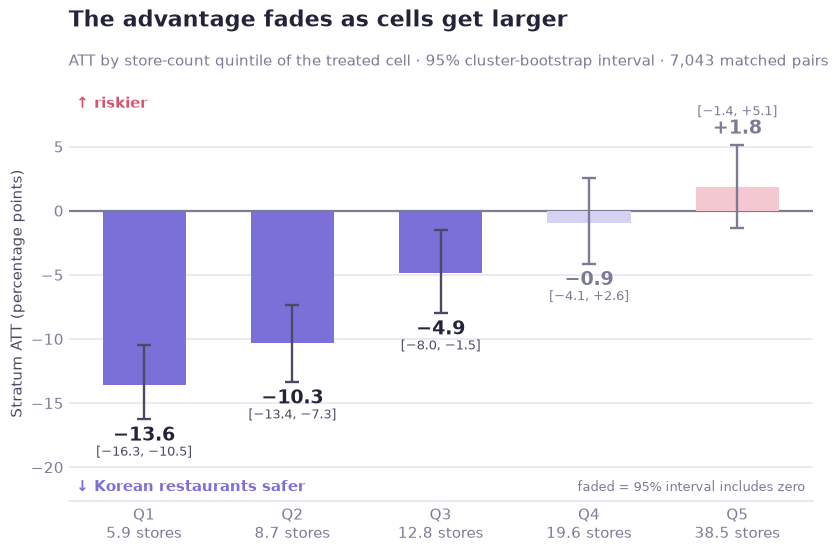

저장: C:\Users\spide\data-projects\seoul-closure-risk\images\strata-att.png


In [4]:
est, lo, hi = strata["층_ATT"] * 100, strata["층_ATT_CI_low"] * 100, strata["층_ATT_CI_high"] * 100
solid = (hi < 0) | (lo > 0)                       # 95% 구간이 0을 포함하지 않는 층만 진하게

fig, ax = plt.subplots(figsize=(9.6, 5.4))
for i, (e, l, h, s) in enumerate(zip(est, lo, hi, solid)):
    base = VIOLET if e < 0 else ROSE
    ax.bar(i, e, width=.56, color=base if s else tint(base, .32), zorder=3)
    ax.errorbar(i, e, yerr=[[e - l], [h - e]], color=INK2 if s else INK3, capsize=5, lw=1.7, capthick=1.7, zorder=4)
    below = e < 0
    y0 = (l - .5) if below else (h + .5)
    ax.text(i, y0, sgn(e), ha="center", va="top" if below else "bottom", fontsize=14, fontweight="bold",
            color=INK if s else INK3, zorder=5)
    ax.text(i, y0 + (-1.55 if below else 1.55), f"[{sgn(l)}, {sgn(h)}]", ha="center", va="top" if below else "bottom",
            fontsize=9.5, color=INK2 if s else INK3, zorder=5)
ax.axhline(0, color=INK3, lw=1.6, zorder=2)
ax.set_xticks(range(len(strata)))
ax.set_xticklabels([f"{q}\n{m:.1f} stores" for q, m in zip(strata.index, strata["평균점포"])], fontsize=11)
ax.set_ylim(lo.min() - 6.4, hi.max() + 4.6)
ax.set_ylabel("Stratum ATT (percentage points)")
clean_axes(ax)
ax.text(0.01, 0.025, "\u2193 Korean restaurants safer", transform=ax.transAxes, color=VIOLET, fontweight="bold", fontsize=11)
ax.text(0.01, 0.975, "\u2191 riskier", transform=ax.transAxes, color=ROSE, fontweight="bold", fontsize=11, ha="left", va="top")
ax.text(0.99, 0.025, "faded = 95% interval includes zero", transform=ax.transAxes, color=INK3, fontsize=9.5, ha="right")
titles(ax, "The advantage fades as cells get larger",
       f"ATT by store-count quintile of the treated cell \u00b7 95% cluster-bootstrap interval \u00b7 {int(att['쌍수']):,} matched pairs")
save(fig, "strata-att")

## 2. gap-reversal — 단순 격차에서 추정량별 격차로

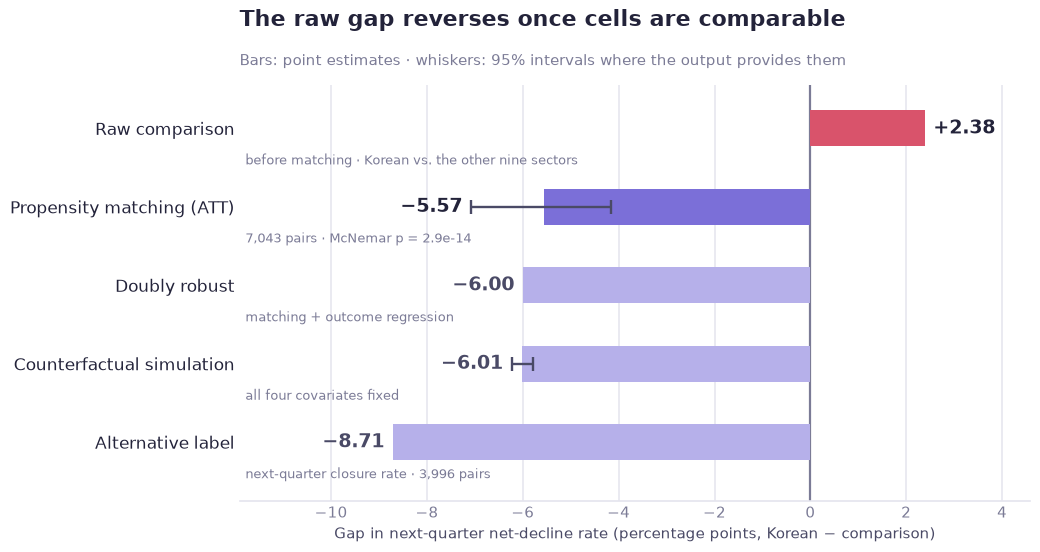

저장: C:\Users\spide\data-projects\seoul-closure-risk\images\gap-reversal.png


In [5]:
cf4 = cf.loc["공변량 4개 전부"]
rows = [  # (label, value, interval, sub-label, color, strength)
    ("Raw comparison", att["매칭전_격차"] * 100, None, "before matching \u00b7 Korean vs. the other nine sectors", ROSE, 1.0),
    ("Propensity matching (ATT)", att["ATT"] * 100, (att["CI_low"] * 100, att["CI_high"] * 100),
     f"{int(att['쌍수']):,} pairs \u00b7 McNemar p = {att['McNemar_p']:.1e}", VIOLET, 1.0),
    ("Doubly robust", att_dr["이중강건_ATT"] * 100, None, "matching + outcome regression", VIOLET, .55),
    ("Counterfactual simulation", cf4["예측격차"] * 100, (cf4["CI_low"] * 100, cf4["CI_high"] * 100),
     "all four covariates fixed", VIOLET, .55),
    ("Alternative label", alt["ATT"] * 100, None, f"next-quarter closure rate \u00b7 {int(alt['쌍수']):,} pairs", VIOLET, .55),
]
vals = [r[1] for r in rows]
ends = vals + [x for r in rows if r[2] for x in r[2]]
xmin, xmax = min(ends) - 3.2, max(ends) + 2.2

fig, ax = plt.subplots(figsize=(10.2, 5.4))
n = len(rows)
for k, (lab, v, ci, sub, col, a) in enumerate(rows):
    y = n - 1 - k
    ax.barh(y, v, height=.46, color=tint(col, a), zorder=3)
    if ci:
        ax.errorbar(v, y, xerr=[[v - ci[0]], [ci[1] - v]], color=INK2, capsize=5, lw=1.7, capthick=1.7, zorder=4)
    edge = (ci[0] if ci else v) if v < 0 else (ci[1] if ci else v)
    ax.text(edge + (-.18 if v < 0 else .18), y, sgn(v, 2), ha="right" if v < 0 else "left", va="center",
            fontsize=14, fontweight="bold", color=INK if a == 1.0 else INK2, zorder=5)
    ax.text(xmin + .12, y - .41, sub, ha="left", va="center", fontsize=9.6, color=INK3)
ax.axvline(0, color=INK3, lw=1.6, zorder=2)
ax.set_yticks(range(n))
ax.set_yticklabels([r[0] for r in rows][::-1], fontsize=12, color=INK)
ax.set_xlim(xmin, xmax)
ax.set_ylim(-.75, n - .45)
ax.set_xlabel("Gap in next-quarter net-decline rate (percentage points, Korean \u2212 comparison)")
clean_axes(ax, "x")
titles(ax, "The raw gap reverses once cells are comparable",
       "Bars: point estimates \u00b7 whiskers: 95% intervals where the output provides them")
save(fig, "gap-reversal")

## 3. operating-point — 상위 K칸 정밀도

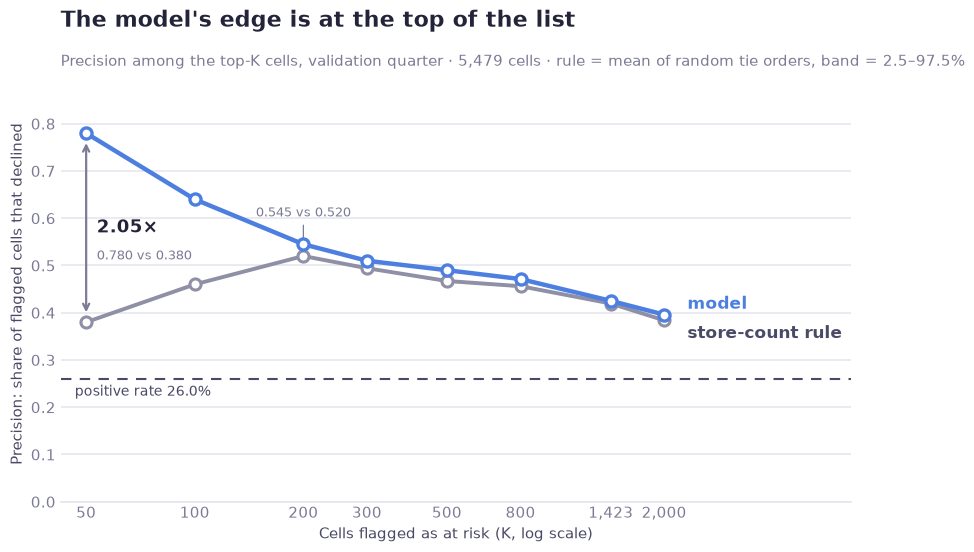

저장: C:\Users\spide\data-projects\seoul-closure-risk\images\operating-point.png


In [6]:
ks = opp.index.to_numpy(dtype=float)
base_rate = (sz["칸수"] * sz["기저율"]).sum() / sz["칸수"].sum()      # 검증 분기 양성률(구간별 기저율의 칸수 가중 평균)
m, r = opp["모델 정밀도"].to_numpy(), opp["점포수 정밀도"].to_numpy()
rlo, rhi = opp["점포수 정밀도 2.5%"].to_numpy(), opp["점포수 정밀도 97.5%"].to_numpy()

fig, ax = plt.subplots(figsize=(10.2, 5.4))
ax.set_xscale("log")
ax.fill_between(ks, rlo, rhi, color=INK3, alpha=.28, lw=0, zorder=2)
ax.plot(ks, r, color=tint(INK3, .85), lw=2.8, marker="o", ms=8, mfc="white", mew=2.2, zorder=3)
ax.plot(ks, m, color=BLUE, lw=3.2, marker="o", ms=8, mfc="white", mew=2.4, zorder=4)
ax.axhline(base_rate, color=INK2, lw=1.5, ls=(0, (5, 4)), zorder=2)
ax.text(ks[0] * .93, base_rate - .012, f"positive rate {base_rate:.1%}", color=INK2, fontsize=10, ha="left", va="top")
ax.set_xticks(ks)
ax.set_xticklabels([f"{int(k):,}" for k in ks], fontsize=10.5)
ax.minorticks_off()
ax.set_xlim(ks[0] * .85, ks[-1] * 3.3)
ax.set_ylim(0, max(m.max(), rhi.max()) + .1)
ax.set_xlabel("Cells flagged as at risk (K, log scale)")
ax.set_ylabel("Precision: share of flagged cells that declined")
clean_axes(ax)
# 직접 라벨
ax.text(ks[-1] * 1.16, m[-1] + .022, "model", color=BLUE, fontsize=12.5, fontweight="bold", va="center")
ax.text(ks[-1] * 1.16, r[-1] - .028, "store-count rule", color=INK2, fontsize=12.5, fontweight="bold", va="center")
# K = 첫 점의 격차 표기
ratio = m[0] / r[0]
ax.annotate("", xy=(ks[0], r[0] + .015), xytext=(ks[0], m[0] - .015), arrowprops=dict(arrowstyle="<->", color=INK3, lw=1.6))
ax.text(ks[0] * 1.07, (m[0] + r[0]) / 2, f"{ratio:.2f}\u00d7", fontsize=13, fontweight="bold", color=INK, va="center")
ax.text(ks[0] * 1.07, (m[0] + r[0]) / 2 - .06, f"{m[0]:.3f} vs {r[0]:.3f}", fontsize=9.5, color=INK3, va="center")
j = list(opp.index).index(200)
ax.annotate(f"{m[j]:.3f} vs {r[j]:.3f}", xy=(ks[j], m[j]), xytext=(0, 20), textcoords="offset points", ha="center",
            fontsize=9.5, color=INK3, arrowprops=dict(arrowstyle="-", color=INK3, lw=.9))
titles(ax, "The model's edge is at the top of the list",
       f"Precision among the top-K cells, validation quarter \u00b7 {int(sz['칸수'].sum()):,} cells \u00b7 rule = mean of random tie orders, band = 2.5\u201397.5%")
save(fig, "operating-point")

## 4. size-strata-lift — 규모 구간별 lift

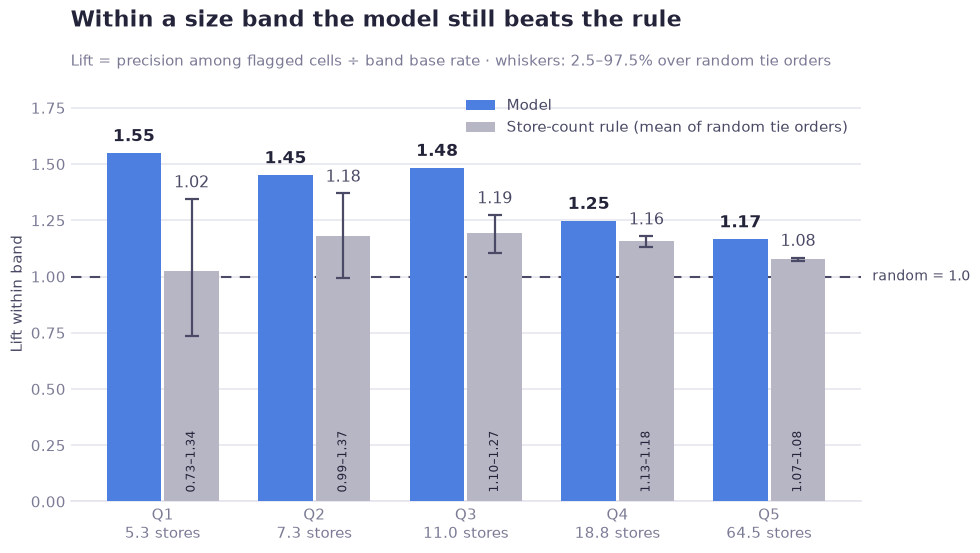

저장: C:\Users\spide\data-projects\seoul-closure-risk\images\size-strata-lift.png


In [7]:
x = np.arange(len(sz)); w = .36
mod, rul = sz["모델 Lift"].to_numpy(), sz["점포수 Lift"].to_numpy()
rl, rh = sz["점포수 Lift 2.5%"].to_numpy(), sz["점포수 Lift 97.5%"].to_numpy()

fig, ax = plt.subplots(figsize=(10.2, 5.4))
ax.bar(x - w / 2 - .01, mod, w, color=BLUE, zorder=3, label="Model")
ax.bar(x + w / 2 + .01, rul, w, color=tint(INK3, .55), zorder=3, label="Store-count rule (mean of random tie orders)")
ax.errorbar(x + w / 2 + .01, rul, yerr=[rul - rl, rh - rul], fmt="none", ecolor=INK2, capsize=5, lw=1.6, capthick=1.6, zorder=4)
for i in range(len(sz)):
    ax.text(x[i] - w / 2 - .01, mod[i] + .035, f"{mod[i]:.2f}", ha="center", va="bottom", fontsize=12.5, fontweight="bold", color=INK)
    ax.text(x[i] + w / 2 + .01, rh[i] + .035, f"{rul[i]:.2f}", ha="center", va="bottom", fontsize=11.5, color=INK2)
    ax.text(x[i] + w / 2 + .01, .04, f"{rl[i]:.2f}\u2013{rh[i]:.2f}", ha="center", va="bottom", fontsize=8.8, color=INK, rotation=90)
ax.axhline(1.0, color=INK2, lw=1.5, ls=(0, (5, 4)), zorder=2)
ax.annotate("random = 1.0", xy=(1.0, 1.0), xycoords=("axes fraction", "data"), xytext=(8, 0), textcoords="offset points",
            fontsize=10, color=INK2, va="center", annotation_clip=False)
ax.set_xticks(x)
ax.set_xticklabels([f"{q}\n{s:.1f} stores" for q, s in zip(sz.index, sz["평균점포"])], fontsize=11)
ax.set_ylim(0, max(mod.max(), rh.max()) + .3)
ax.set_ylabel("Lift within band")
clean_axes(ax)
ax.legend(loc="upper right", frameon=False, fontsize=10.5, labelcolor=INK2)
titles(ax, "Within a size band the model still beats the rule",
       "Lift = precision among flagged cells \u00f7 band base rate \u00b7 whiskers: 2.5\u201397.5% over random tie orders")
save(fig, "size-strata-lift")

## 5. forecast — 2026Q2 업종별 예측 폐업률과 순감소 순위

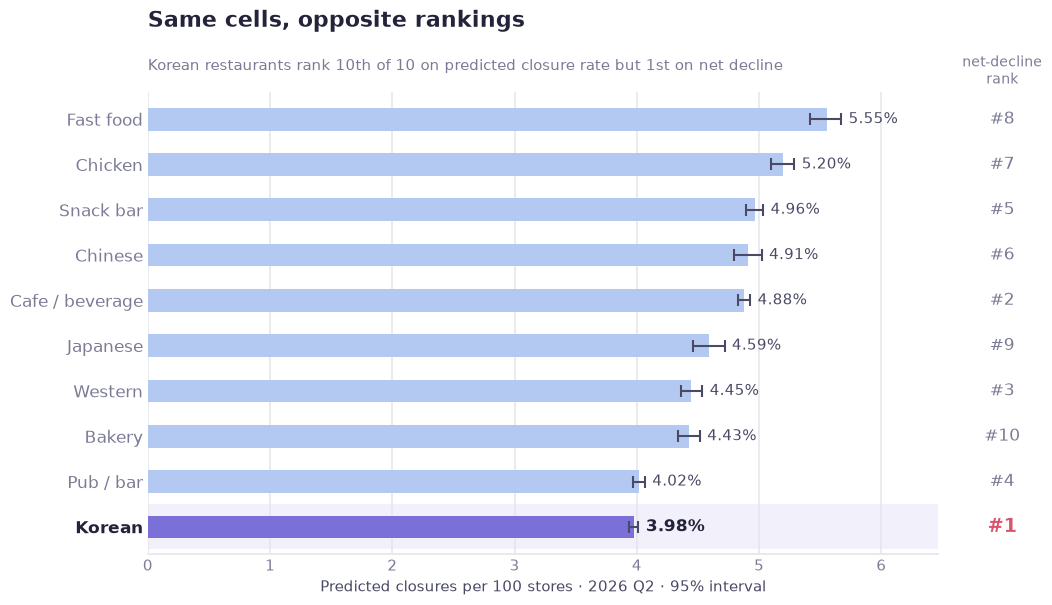

저장: C:\Users\spide\data-projects\seoul-closure-risk\images\forecast.png


In [8]:
EN = {"패스트푸드점": "Fast food", "치킨전문점": "Chicken", "분식전문점": "Snack bar", "중식음식점": "Chinese", "커피-음료": "Cafe / beverage",
      "일식음식점": "Japanese", "양식음식점": "Western", "제과점": "Bakery", "호프-간이주점": "Pub / bar", "한식음식점": "Korean"}
d = fc.join(fci[["CI_low", "CI_high"]]).sort_values("예측_폐업률", ascending=False)
focus = "한식음식점"
n = len(d)

fig, ax = plt.subplots(figsize=(10.2, 6.0))
for k, (name, row) in enumerate(d.iterrows()):
    y = n - 1 - k
    is_f = name == focus
    if is_f:
        ax.axhspan(y - .5, y + .5, color=tint(VIOLET, .10), zorder=0, lw=0)
    ax.barh(y, row["예측_폐업률"], height=.5, color=VIOLET if is_f else tint(BLUE, .42), zorder=3)
    ax.errorbar(row["예측_폐업률"], y, xerr=[[row["예측_폐업률"] - row["CI_low"]], [row["CI_high"] - row["예측_폐업률"]]],
                color=INK2, capsize=4, lw=1.5, capthick=1.5, zorder=4)
    ax.text(row["CI_high"] + .06, y, f"{row['예측_폐업률']:.2f}%", va="center", fontsize=12 if is_f else 11,
            fontweight="bold" if is_f else "normal", color=INK if is_f else INK2)
    rk = int(row["순감소_순위"])
    ax.annotate(f"#{rk}", xy=(1.0, y), xycoords=("axes fraction", "data"), xytext=(46, 0), textcoords="offset points",
                ha="center", va="center", fontsize=14 if rk == 1 else 12, fontweight="bold" if rk == 1 else "normal",
                color=ROSE if rk == 1 else INK3, annotation_clip=False)
ax.annotate("net-decline\nrank", xy=(1.0, n - .5), xycoords=("axes fraction", "data"), xytext=(46, 6), textcoords="offset points",
            ha="center", va="bottom", fontsize=10, color=INK3, annotation_clip=False)
ax.set_yticks(range(n))
ax.set_yticklabels([EN[s] for s in d.index][::-1], fontsize=12)
for t in ax.get_yticklabels():
    if t.get_text() == EN[focus]:
        t.set_fontweight("bold"); t.set_color(INK)
ax.set_xlim(0, d["CI_high"].max() * 1.14)
ax.set_ylim(-.6, n - .4)
ax.set_xlabel("Predicted closures per 100 stores \u00b7 2026 Q2 \u00b7 95% interval")
clean_axes(ax, "x")
fr = int(d.loc[focus, "폐업률_순위"]); fn = int(d.loc[focus, "순감소_순위"])
titles(ax, "Same cells, opposite rankings",
       f"Korean restaurants rank {fr}th of {n} on predicted closure rate but {fn}st on net decline")
save(fig, "forecast")

In [9]:
# ── 요약: 각 그림에 들어간 핵심 값 (모두 CSV 에서) ───────────────
print("strata-att      :", ", ".join(f"{q} {sgn(e)} [{sgn(l)}, {sgn(h)}] ({m:.1f} stores)" for q, e, l, h, m in zip(strata.index, est, lo, hi, strata["평균점포"])))
print("gap-reversal    :", ", ".join(f"{r_[0]} {sgn(r_[1], 2)}" for r_ in rows))
print(f"operating-point : K={int(ks[0])} model {m[0]:.3f} vs rule {r[0]:.3f} ({ratio:.2f}x); K=200 {m[j]:.3f} vs {r[j]:.3f}; K={int(ks[-1])} {m[-1]:.3f} vs {r[-1]:.3f}; positive rate {base_rate:.3f}")
print("size-strata-lift:", ", ".join(f"{q} {a:.3f} vs {b:.3f} [{c:.2f}-{d_:.2f}]" for q, a, b, c, d_ in zip(sz.index, mod, rul, rl, rh)))
print("forecast        :", ", ".join(f"{EN[s]} {v:.2f}% (#{int(k)})" for s, v, k in zip(d.index, d["예측_폐업률"], d["순감소_순위"])))

strata-att      : Q1 −13.6 [−16.3, −10.5] (5.9 stores), Q2 −10.3 [−13.4, −7.3] (8.7 stores), Q3 −4.9 [−8.0, −1.5] (12.8 stores), Q4 −0.9 [−4.1, +2.6] (19.6 stores), Q5 +1.8 [−1.4, +5.1] (38.5 stores)
gap-reversal    : Raw comparison +2.38, Propensity matching (ATT) −5.57, Doubly robust −6.00, Counterfactual simulation −6.01, Alternative label −8.71
operating-point : K=50 model 0.780 vs rule 0.380 (2.05x); K=200 0.545 vs 0.520; K=2000 0.396 vs 0.384; positive rate 0.260
size-strata-lift: Q1 1.548 vs 1.022 [0.73-1.34], Q2 1.450 vs 1.180 [0.99-1.37], Q3 1.483 vs 1.192 [1.10-1.27], Q4 1.247 vs 1.159 [1.13-1.18], Q5 1.166 vs 1.079 [1.07-1.08]
forecast        : Fast food 5.55% (#8), Chicken 5.20% (#7), Snack bar 4.96% (#5), Chinese 4.91% (#6), Cafe / beverage 4.88% (#2), Japanese 4.59% (#9), Western 4.45% (#3), Bakery 4.43% (#10), Pub / bar 4.02% (#4), Korean 3.98% (#1)
